# Try IMSTE on a native single-cell dataset

The loader, embedding configuration, and plotting code live in `imste_single_cell.py`. This notebook keeps the experiment runnable in a few cells. Choose an original high-dimensional H5AD file from `data/` in the selector below.

Only original files are listed; PCCA, PCA, scALP, and CLASP variants are excluded. The loader uses the original `X` matrix and reads it in read-only mode. Set `MAX_CELLS` in the loading cell to choose a reproducible subset.


In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2
from pathlib import Path
import sys
import importlib.util

import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.random_projection import GaussianRandomProjection

NOTEBOOK_DIR = next(
    (parent / "notebooks" for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "notebooks" / "imste_single_cell.py").is_file()),
    Path.cwd(),
)
if not (NOTEBOOK_DIR / "imste_single_cell.py").is_file():
    NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import imste_single_cell
from imste_single_cell import (
    available_datasets,
    available_obs_columns,
    fit_embedding,
    load_dataset_with_train_test,
    plot_cell_counts,
    plot_mst_edges,
)
import pandas as pd

RPC_ROOT = Path("/Users/f.costa/Code/RecursiveParitionClassifier")
if not (RPC_ROOT / "recursive_partition" / "__init__.py").is_file():
    raise FileNotFoundError(f"RecursivePartitionClassifier checkout not found: {RPC_ROOT}")
RPC_NOTEBOOKS = RPC_ROOT / "notebooks"
for import_path in (RPC_ROOT, RPC_NOTEBOOKS):
    if str(import_path) not in sys.path:
        sys.path.insert(0, str(import_path))
from recursive_partition import BaggedRecursivePartitionClassifier
from bagged_partition_imste_embeddings import describe_base_models, make_base_models

# Load the reusable visualization functions from the IMSTE repository checkout.
IMSTE_VISUALIZATION_PATH = Path(
    "/Users/f.costa/Code/IteratedMinimumSpanningTree/imste/visualization.py"
)
if not IMSTE_VISUALIZATION_PATH.is_file():
    raise FileNotFoundError(f"IMSTE visualization utilities not found: {IMSTE_VISUALIZATION_PATH}")
_visualization_spec = importlib.util.spec_from_file_location(
    "imste_visualization_tools", IMSTE_VISUALIZATION_PATH
)
imste_visualization = importlib.util.module_from_spec(_visualization_spec)
_visualization_spec.loader.exec_module(imste_visualization)
plot_embedding = imste_visualization.plot_embedding
plot_knn_union = imste_visualization.plot_knn_union
plot_ellipses = imste_visualization.plot_ellipses
interactive_force = imste_visualization.interactive_force


## Choose original dataset

Select one of the original high-dimensional H5AD files available in `data/`. PCCA, PCA, scALP, and CLASP variants are excluded. The default is the original human pancreas dataset.

After changing the selector, rerun the data-loading cell, the fit cell, and then the plot cell.


In [2]:
DEFAULT_DATASET_NAME = "human_pancreas_norm_complexBatch.h5ad"
AVAILABLE_DATASETS = available_datasets()
DATASET_OPTIONS = [(path.name, str(path)) for path in AVAILABLE_DATASETS]
DEFAULT_DATASET_PATH = next(
    value for name, value in DATASET_OPTIONS if name == DEFAULT_DATASET_NAME
)
try:
    import ipywidgets as widgets
    from IPython.display import display

    DATASET_SELECTOR = widgets.Dropdown(
        options=DATASET_OPTIONS,
        value=DEFAULT_DATASET_PATH,
        description="Dataset:",
        layout=widgets.Layout(width="80%"),
    )
    display(DATASET_SELECTOR)
except ImportError:
    DATASET_SELECTOR = None
    DATASET_NAME = DEFAULT_DATASET_NAME
    print("Available datasets:", ", ".join(path.name for path in AVAILABLE_DATASETS))
    print("Set DATASET_NAME to the file to load.")


Dropdown(description='Dataset:', index=9, layout=Layout(width='80%'), options=(('Immune_ALL_hum_mou.h5ad', '/U…

Dataset: human_pancreas_norm_complexBatch.h5ad
Representation: X
NumPy representation: (8000, 19093), dtype=float32
Training rows: 500 (up to 50 per class)
Test rows: 8,000 / MAX_CELLS=8,000
Classes retained: 10 (minimum 50 cells in source)
Excluded classes below the minimum:


,source cells
celltype,
7,32
10,42
12,25
13,7


Class label: celltype (10 classes)
Metadata columns: ['_index', 'celltype', 'size_factors', 'tech']


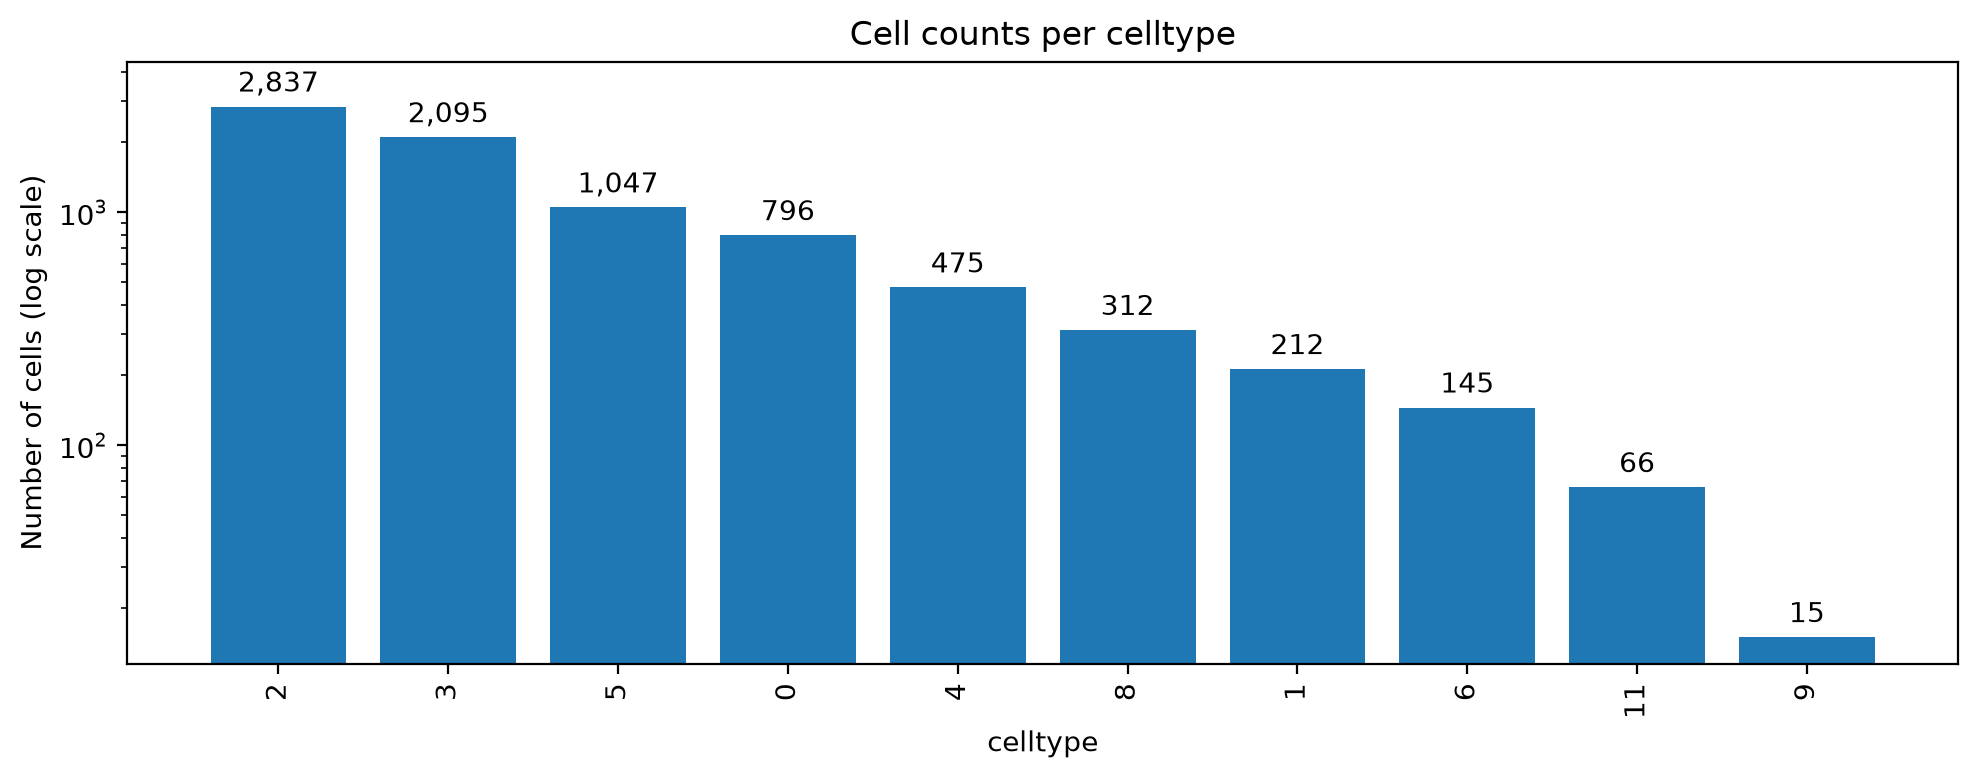

,_index,celltype,size_factors,tech
human4_lib1.final_cell_0384,human4_lib1.final_cell_0384,2,0.030171,6
D17All2_55,D17All2_55,3,0.093156,0
HP1525301T2D_G9,HP1525301T2D_G9,5,2.164755,8
D3en4_92,D3en4_92,0,0.091919,0
human1_lib3.final_cell_0278,human1_lib3.final_cell_0278,4,0.020770,3


In [3]:
DATASET_PATH = (
    DATASET_SELECTOR.value
    if DATASET_SELECTOR is not None
    else next(path for path in AVAILABLE_DATASETS if path.name == DATASET_NAME)
)
MATRIX_KEY = "X"
MAX_CELLS = 8000
TRAIN_INSTANCES_PER_CLASS = 50
MIN_CELLS_PER_CLASS = 50
(
    X_train_raw,
    obs_train,
    train_row_indices,
    X,
    obs,
    row_indices,
    LABEL_KEY,
    excluded_class_counts,
) = (
    load_dataset_with_train_test(
        path=DATASET_PATH,
        matrix_key=MATRIX_KEY,
        obs_keys=tuple(available_obs_columns(DATASET_PATH)),
        max_test_cells=MAX_CELLS,
        train_instances_per_class=TRAIN_INSTANCES_PER_CLASS,
        min_cells_per_class=MIN_CELLS_PER_CLASS,
        random_state=42,
    )
)
obs_test = obs
print(f"Dataset: {Path(DATASET_PATH).name}")
print(f"Representation: {MATRIX_KEY}")
print(f"NumPy representation: {X.shape}, dtype={X.dtype}")
print(f"Training rows: {len(train_row_indices):,} (up to {TRAIN_INSTANCES_PER_CLASS} per class)")
print(f"Test rows: {len(row_indices):,} / MAX_CELLS={MAX_CELLS:,}")
print(f"Classes retained: {obs[LABEL_KEY].nunique()} (minimum {MIN_CELLS_PER_CLASS} cells in source)")
if not excluded_class_counts.empty:
    print("Excluded classes below the minimum:")
    display(excluded_class_counts.rename("source cells").to_frame())
print(f"Class label: {LABEL_KEY} ({obs[LABEL_KEY].nunique()} classes)")
print("Metadata columns:", list(obs.columns))
fig, ax = plot_cell_counts(obs, LABEL_KEY, log_scale=True)
plt.show()
obs.head()


## Build the representation and fit IMSTE

Classes with fewer than `MIN_CELLS_PER_CLASS` cells in the source dataset are excluded. For each retained class, up to `TRAIN_INSTANCES_PER_CLASS` rows are sampled for classifier training, leaving at least one row for the disjoint test set. The test set includes up to `MAX_CELLS` remaining cells. Partition features can be combined with the original standardized features. `NORMALIZE_FEATURE_BLOCK = True` normalizes block norms using training rows only. `FEATURE_BLOCK_ALPHA` sets the original block weight; the partition block gets `1 - alpha`.


In [4]:
# The loader filters rare classes and provides disjoint train/test rows.
RANDOM_STATE = 42
y_train = obs_train[LABEL_KEY].to_numpy()
y_test = obs_test[LABEL_KEY].to_numpy()
train_class_counts = obs_train[LABEL_KEY].value_counts()

# Fit preprocessing on training rows only, then transform the test set.
input_scaler = StandardScaler()
X_train = input_scaler.fit_transform(X_train_raw.astype(np.float32))
X_test = input_scaler.transform(X.astype(np.float32))

BAGGING_N_ESTIMATORS = 30
MAX_DEPTH = 5
BASE_MODELS = make_base_models(
    max_depth=MAX_DEPTH,
    mlp_hidden_layer_sizes=(64, 64, 32),
)
describe_base_models(BASE_MODELS)
MODELS_TO_RUN = ["Linear SVM"]
if len(MODELS_TO_RUN) != 1:
    raise ValueError("Choose exactly one base model in MODELS_TO_RUN.")
MODEL_NAME = MODELS_TO_RUN[0]
if MODEL_NAME not in BASE_MODELS:
    raise ValueError(f"Unknown model {MODEL_NAME!r}; choose from {tuple(BASE_MODELS)}.")

# Keep node-incidence features intact unless they exceed the original width.
MAX_PARTITION_COMPONENTS = X_train.shape[1]
INCLUDE_ORIGINAL_FEATURES = True
NORMALIZE_FEATURE_BLOCK = True
FEATURE_BLOCK_ALPHA = 0.75
CLASSIFIER_PARAMETERS = {
    "estimator": BASE_MODELS[MODEL_NAME],
    "n_estimators": BAGGING_N_ESTIMATORS,
    "max_samples": 1.0,
    "bootstrap": True,
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
    "aggregation": "mean_proba",
    "oob_score": False,
    "verbose": 0,
    "max_depth": MAX_DEPTH,
    # Fit the original node-incidence representation first so its width can
    # decide whether a random projection is actually needed.
    "n_components": None,
}
pd.Series(CLASSIFIER_PARAMETERS, name="value").rename_axis("parameter").to_frame()

classifier = BaggedRecursivePartitionClassifier(**CLASSIFIER_PARAMETERS)
classifier.fit(X_train, y_train)
partition_train_nodes = classifier.transform(X_train)
partition_test_nodes = classifier.transform(X_test)
N_PARTITION_FEATURES = partition_train_nodes.shape[1]
if N_PARTITION_FEATURES > MAX_PARTITION_COMPONENTS:
    partition_projection = GaussianRandomProjection(
        n_components=MAX_PARTITION_COMPONENTS,
        random_state=RANDOM_STATE,
    )
    partition_train = partition_projection.fit_transform(partition_train_nodes)
    partition_test = partition_projection.transform(partition_test_nodes)
    print(
        f"Randomly projected partition features: {N_PARTITION_FEATURES:,} "
        f"to {MAX_PARTITION_COMPONENTS:,}."
    )
else:
    partition_train = partition_train_nodes.toarray()
    partition_test = partition_test_nodes.toarray()
    print(
        f"Using original dense partition features: "
        f"{N_PARTITION_FEATURES:,} columns (input width {X_train.shape[1]:,})."
    )
partition_scaler = StandardScaler()
partition_scaler.fit(partition_train)
partition_train_scaled = partition_scaler.transform(partition_train)
partition_test_scaled = partition_scaler.transform(partition_test)
if partition_test_scaled.shape[1] != partition_train.shape[1]:
    raise ValueError("Train and test partition feature widths must match.")
if INCLUDE_ORIGINAL_FEATURES:
    imste_features, FEATURE_BLOCK_SCALES = imste_single_cell.combine_feature_blocks(
        X_train,
        X_test,
        partition_train_scaled,
        partition_test_scaled,
        normalize_blocks=NORMALIZE_FEATURE_BLOCK,
        alpha=FEATURE_BLOCK_ALPHA,
    )
    print(f"Feature block scales: {FEATURE_BLOCK_SCALES}")
else:
    imste_features = partition_test_scaled
    FEATURE_BLOCK_SCALES = {"partition": 1.0}

print(f"Dataset: {Path(DATASET_PATH).name}")
print(f"Classifier model: {MODEL_NAME}; bagged estimators: {len(classifier.estimators_)}")
print(f"Classifier training rows: {len(train_row_indices):,}; up to {TRAIN_INSTANCES_PER_CLASS} per class")
print(f"Disjoint test rows: {len(row_indices):,} / MAX_CELLS={MAX_CELLS:,}")
print(f"Original test features: {X_test.shape}")
print(f"Partition test features: {partition_test_scaled.shape}")
print(f"IMSTE input features: {imste_features.shape}")
print(f"Held-out classifier accuracy: {classifier.score(X_test, y_test):.3f}")

EMBEDDER_PARAMS = {
    "n_msts": 50,
    "n_components": 2,
    "n_epochs": 1500,
    "batch_size": 131_072,
    "learning_rate": 0.05,
    "negative_ratio": 30,
    "lambda_rep": 0.5,
    "random_state": RANDOM_STATE,
    "epsilon": 1e-4,
    "logistic_margin": 1.0,
    "logistic_temperature": 0.5,
    "mst_method": "famst",
    "mst_neighbors": 64,
    "mst_inter_component_edges": 5,
    "mst_max_neighbors": 512,
    "mst_representatives_per_component": 10,
    "device": "mps",  # Change to "auto" or "cpu" if needed.
    "progress_callback": None,
    "mst_progress_callback": None,
}
pd.Series(EMBEDDER_PARAMS, name="value").rename_axis("parameter").to_frame()

AUTO_MST_FALLBACK = True
MST_FALLBACK_MAX_DENSE_GB = 1.0
estimator, embedding = fit_embedding(
    imste_features,
    EMBEDDER_PARAMS,
    auto_mst_fallback=AUTO_MST_FALLBACK,
    fallback_dense_memory_gb=MST_FALLBACK_MAX_DENSE_GB,
)
print(f"Held-out embedding: {embedding.shape}")


Available recursive partition models
Linear SVM
  partition depth: 5
  split estimator: SVC(kernel='linear', C=10.0, class_weight='balanced')
Quadratic SVM
  partition depth: 5
  split estimator: SVC(kernel='poly', degree=2, coef0=1.0, gamma='scale', C=1.0, class_weight='balanced')
RBF SVM
  partition depth: 5
  split estimator: SVC(kernel='rbf', gamma='scale', C=1.0, class_weight='balanced')
QDA
  partition depth: 5
  split estimator: EqualPriorQDA(reg_param=0.05)
MLP
  partition depth: 5
  split estimator: MLPClassifierAdapter(hidden_layer_sizes=(64, 64, 32), solver='adam', max_iter=1000, tol=0.01, class_weight='balanced', random_state=42)
Gaussian process
  partition depth: 5
  split estimator: GaussianProcessClassifierAdapter(optimizer=None, max_iter_predict=50, class_weight='balanced', random_state=42)
Using original dense partition features: 330 columns (input width 19,093).
Feature block scales: {'original': np.float64(0.005765138631983958), 'partition': np.float64(0.01443375672

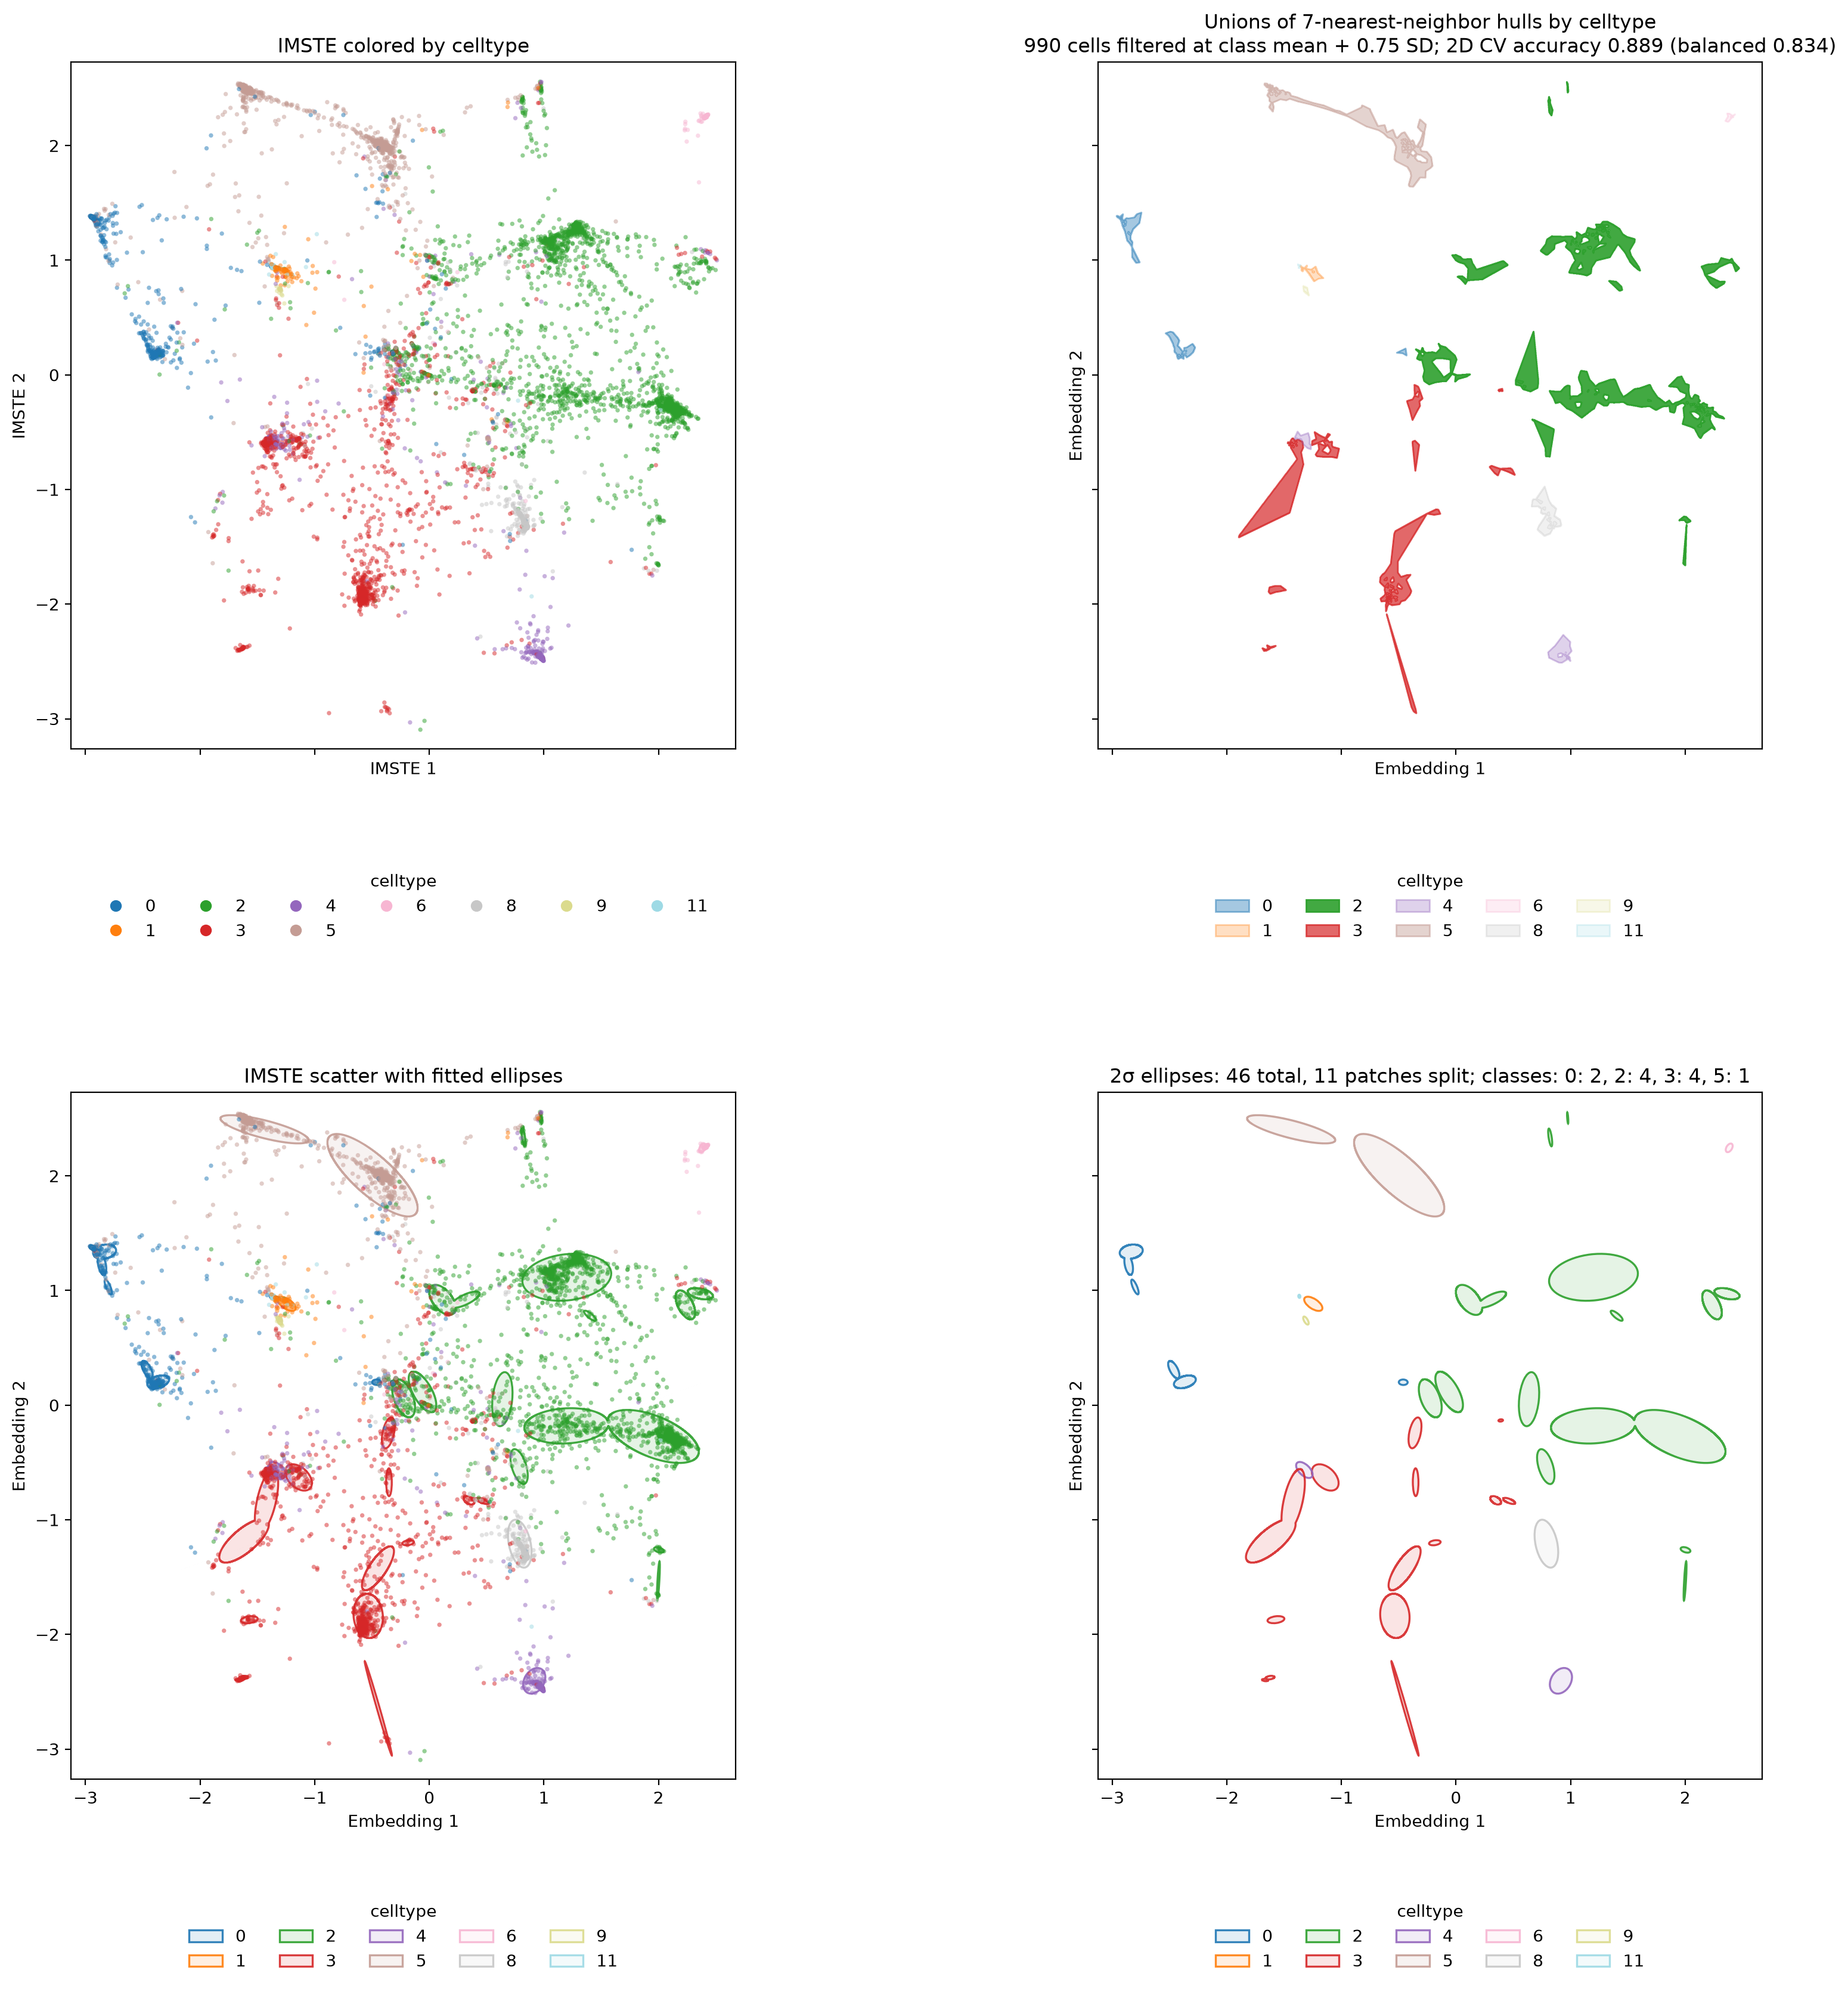

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(20, 20), sharex=True, sharey=True)

K_NEIGHBORS = 7
CV_NEIGHBORS = 30
CV_FOLDS = 5
DISTANCE_STD_THRESHOLD = 0.75
PATCH_ALPHA_RANGE = (0.2, 0.9)
ELLIPSE_N_STD = 2.0
ELLIPSE_MAX_PER_PATCH = 2
ELLIPSE_MIN_PRECISION = 0.7
ELLIPSE_MIN_RECALL = 0.7
PLOT_RANDOM_STATE = RANDOM_STATE

# Top left: all points in the existing 2D embedding.
plot_embedding(
    embedding,
    obs_test,
    color_keys=(LABEL_KEY,),
    point_alpha=0.5,
    ax=axes[0, 0],
    legend_position="bottom",
)

# Top right: cross-validated, filtered kNN neighborhood hull unions.
plot_knn_union(
    embedding,
    obs_test,
    label_key=LABEL_KEY,
    k=K_NEIGHBORS,
    alpha_range=PATCH_ALPHA_RANGE,
    cv_neighbors=CV_NEIGHBORS,
    cv_splits=CV_FOLDS,
    random_state=PLOT_RANDOM_STATE,
    distance_std_threshold=DISTANCE_STD_THRESHOLD,
    ax=axes[0, 1],
    legend_position="bottom",
)

# Bottom left: the same filtered ellipses over the 50%-alpha scatter.
plot_ellipses(
    embedding,
    obs_test,
    label_key=LABEL_KEY,
    k=K_NEIGHBORS,
    cv_neighbors=CV_NEIGHBORS,
    cv_splits=CV_FOLDS,
    random_state=PLOT_RANDOM_STATE,
    distance_std_threshold=DISTANCE_STD_THRESHOLD,
    n_std=ELLIPSE_N_STD,
    max_ellipses_per_region=ELLIPSE_MAX_PER_PATCH,
    min_precision=ELLIPSE_MIN_PRECISION,
    min_recall=ELLIPSE_MIN_RECALL,
    point_alpha=0.5,
    ax=axes[1, 0],
    legend_position="bottom",
)
axes[1, 0].set_title("IMSTE scatter with fitted ellipses")

# Bottom right: call the same ellipse utility with invisible scatter points.
plot_ellipses(
    embedding,
    obs_test,
    label_key=LABEL_KEY,
    k=K_NEIGHBORS,
    cv_neighbors=CV_NEIGHBORS,
    cv_splits=CV_FOLDS,
    random_state=PLOT_RANDOM_STATE,
    distance_std_threshold=DISTANCE_STD_THRESHOLD,
    n_std=ELLIPSE_N_STD,
    max_ellipses_per_region=ELLIPSE_MAX_PER_PATCH,
    min_precision=ELLIPSE_MIN_PRECISION,
    min_recall=ELLIPSE_MIN_RECALL,
    point_alpha=0.0,
    ax=axes[1, 1],
    legend_position="bottom",
)

x_min, x_max = embedding[:, 0].min(), embedding[:, 0].max()
y_min, y_max = embedding[:, 1].min(), embedding[:, 1].max()
x_pad = 0.03 * (x_max - x_min)
y_pad = 0.03 * (y_max - y_min)
for ax in axes.ravel():
    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)
    ax.set_aspect("equal", adjustable="box")
fig.subplots_adjust(wspace=0.25, hspace=0.5, bottom=0.16)
plt.show()


In [ ]:
# Interactive label-guided adjustment of the current 2D embedding.
interactive_force(
    embedding,
    obs_test,
    label_key=LABEL_KEY,
    initial_k=10,
    initial_iterations=20,
    initial_distance_fraction=0.25,
    max_k=50,
    max_iterations=200,
)
